# Practical No. 7

## Aim: To perform an analysis of Ensemble Technique.

In [ ]:
# Name: Rudraksh K Ramekar
# Roll No.: 69
# Branch: B.E. Data Science
# Year: 4th - C
# Sem: VII

## 1. Install and Import Required Libraries

In [5]:
!pip install kagglehub

## 2. Download the Dataset from Kaggle

In [8]:
import kagglehub

path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

print(path)

C:\Users\ASUS\.cache\kagglehub\datasets\uciml\breast-cancer-wisconsin-data\versions\2


## 3. Display the Files in the Dataset

In [11]:
import os

print(os.listdir(path))

['data.csv']


## 4. Load the Dataset

In [14]:
import pandas as pd

df = pd.read_csv(path + "/data.csv")

df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 5. Display the Shape and Column Names of the Dataset

In [19]:
print("Number of Rows and Columns:", df.shape)
print(df.columns)

Number of Rows and Columns: (569, 33)
Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')


## 6. Check for Missing Values

In [23]:
print(df.isnull().sum())

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

## 7. Remove Unnecessary Columns

In [26]:
df = df.drop(['id', 'Unnamed: 32'], axis=1)

df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 8. Convert the Target Variable into Numerical Values

In [29]:
df['diagnosis'] = df['diagnosis'].map({'B': 0, 'M': 1})

df['diagnosis'].value_counts()

diagnosis
0    357
1    212
Name: count, dtype: int64

## 9. Separate Features and Target Variable

In [32]:
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (569, 30)
Target Shape: (569,)


## 10. Split the Dataset into Training and Testing Data

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


## 11. Standardize the Features

In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 12. Create Individual Machine Learning Models

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

model1 = LogisticRegression(max_iter=1000, random_state=42)
model2 = SVC(kernel='linear', probability=True, random_state=42)
model3 = RandomForestClassifier(n_estimators=100, random_state=42)

print("Models created successfully.")

Models created successfully.


## 13. Create the Voting Ensemble Model

In [44]:
from sklearn.ensemble import VotingClassifier

ensemble_model = VotingClassifier(
    estimators=[
        ('logistic_regression', model1),
        ('svm', model2),
        ('random_forest', model3)
    ],
    voting='soft'
)

ensemble_model.fit(X_train_scaled, y_train)

print("Voting Ensemble Model trained successfully.")

Voting Ensemble Model trained successfully.


## 14. Make Predictions Using the Ensemble Model

In [47]:
y_pred = ensemble_model.predict(X_test_scaled)

print(y_pred)

[0 1 0 1 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 1 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 0 1]


## 15. Calculate the Accuracy of the Ensemble Model

In [50]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Ensemble Model Accuracy:", accuracy)
print("Ensemble Model Accuracy: {:.2f}%".format(accuracy * 100))

Ensemble Model Accuracy: 0.9736842105263158
Ensemble Model Accuracy: 97.37%


## 16. Generate the Confusion Matrix

In [53]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[72  0]
 [ 3 39]]


## 17. Display the Classification Report

In [56]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['Benign', 'Malignant']
))

              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



## 18. Visualize the Confusion Matrix

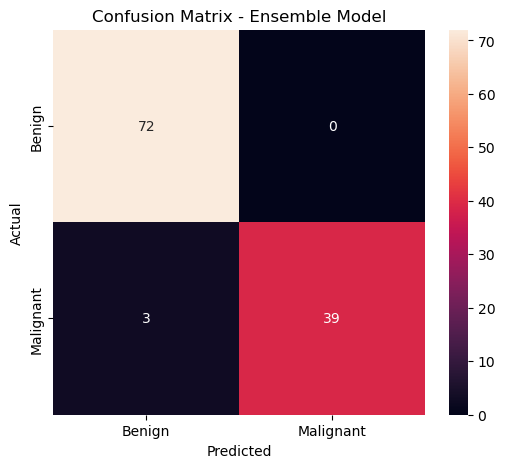

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Ensemble Model')
plt.show()

## 19. Compare Individual Models with the Ensemble Model

In [62]:
model1.fit(X_train_scaled, y_train)
model2.fit(X_train_scaled, y_train)
model3.fit(X_train_scaled, y_train)

pred_lr = model1.predict(X_test_scaled)
pred_svm = model2.predict(X_test_scaled)
pred_rf = model3.predict(X_test_scaled)

acc_lr = accuracy_score(y_test, pred_lr)
acc_svm = accuracy_score(y_test, pred_svm)
acc_rf = accuracy_score(y_test, pred_rf)
acc_ensemble = accuracy_score(y_test, y_pred)

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'SVM',
        'Random Forest',
        'Voting Ensemble'
    ],
    'Accuracy': [
        acc_lr,
        acc_svm,
        acc_rf,
        acc_ensemble
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.964912
1,SVM,0.964912
2,Random Forest,0.973684
3,Voting Ensemble,0.973684


## 20. Visualize Model Accuracy Comparison

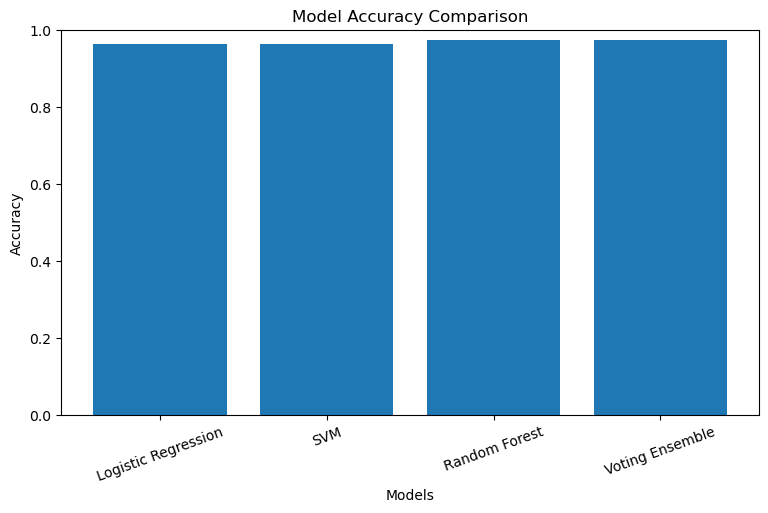

In [65]:
plt.figure(figsize=(9, 5))

plt.bar(results['Model'], results['Accuracy'])

plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')

plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

## 21. Display Accuracy in Percentage

In [68]:
results['Accuracy (%)'] = results['Accuracy'] * 100

results[['Model', 'Accuracy (%)']]

,Model,Accuracy (%)
0,Logistic Regression,96.491228
1,SVM,96.491228
2,Random Forest,97.368421
3,Voting Ensemble,97.368421
